# Home Loan Data Analysis — Deep Learning

**Objective:** predict whether an applicant will be able to repay a loan (`TARGET = 1` means the client had payment difficulties / default).
Steps from the brief: load data → null check → default percentage → balance → plot → encode → deep learning model → **sensitivity** and **ROC-AUC**.

In [1]:
import os, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve,
                             classification_report, recall_score)
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100

## 1. Load the dataset

In [2]:
df = pd.read_csv("../loan_data-2.csv")
print(df.shape)
df.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Null values

Columns with nulls: 67 of 122
Columns with > 40% nulls: 49


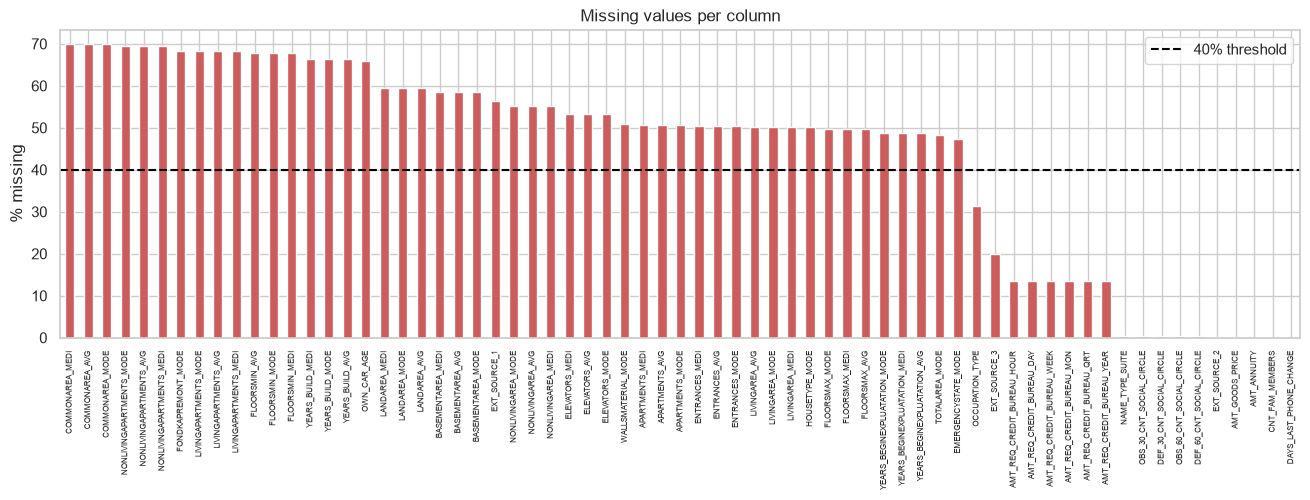

COMMONAREA_MEDI             69.87
COMMONAREA_AVG              69.87
COMMONAREA_MODE             69.87
NONLIVINGAPARTMENTS_MODE    69.43
NONLIVINGAPARTMENTS_AVG     69.43
NONLIVINGAPARTMENTS_MEDI    69.43
FONDKAPREMONT_MODE          68.39
LIVINGAPARTMENTS_MODE       68.35
LIVINGAPARTMENTS_AVG        68.35
LIVINGAPARTMENTS_MEDI       68.35
FLOORSMIN_AVG               67.85
FLOORSMIN_MODE              67.85
FLOORSMIN_MEDI              67.85
YEARS_BUILD_MEDI            66.50
YEARS_BUILD_MODE            66.50
dtype: float64

In [3]:
null_pct = df.isna().mean().mul(100).sort_values(ascending=False)
print(f"Columns with nulls: {(null_pct > 0).sum()} of {df.shape[1]}")
print(f"Columns with > 40% nulls: {(null_pct > 40).sum()}")
plt.figure(figsize=(16, 4))
null_pct[null_pct > 0].plot.bar(color="indianred"); plt.axhline(40, ls="--", color="black", label="40% threshold")
plt.ylabel("% missing"); plt.title("Missing values per column"); plt.xticks(fontsize=6); plt.legend(); plt.show()
null_pct.head(15).round(2)

**Treatment:** columns with more than 40% missing (mostly building-description fields `*_AVG/_MODE/_MEDI`) are dropped. Remaining numeric
nulls are filled with the **median** (fitted on training data) and categorical nulls with an explicit `"Missing"` category.
`DAYS_EMPLOYED = 365243` is a placeholder for "not employed / pensioner" and is converted to NaN plus a flag.

## 3. Percentage of defaulters vs payers

In [4]:
pct = df["TARGET"].value_counts(normalize=True).mul(100).rename({0: "Payer (0)", 1: "Defaulter (1)"})
print(pct.round(2))
print(f"\nDefault : payer ratio = 1 : {df['TARGET'].value_counts()[0] / df['TARGET'].value_counts()[1]:.1f}")

TARGET
Payer (0)        91.93
Defaulter (1)     8.07
Name: proportion, dtype: float64

Default : payer ratio = 1 : 11.4


Only **~8.1% of applicants default** — the data is highly imbalanced (≈ 1 : 11.4).

## 6. Encoding & preprocessing (done before balancing so the model sees the same features)

In [5]:
data = df.drop(columns=["SK_ID_CURR"]).copy()
data = data.drop(columns=null_pct[null_pct > 40].index)
data["DAYS_EMPLOYED_ANOM"] = (data["DAYS_EMPLOYED"] == 365243).astype(int)
data["DAYS_EMPLOYED"] = data["DAYS_EMPLOYED"].replace(365243, np.nan)
# A few helpful ratio features
data["CREDIT_INCOME_RATIO"] = data["AMT_CREDIT"] / data["AMT_INCOME_TOTAL"]
data["ANNUITY_INCOME_RATIO"] = data["AMT_ANNUITY"] / data["AMT_INCOME_TOTAL"]
data["CREDIT_TERM"] = data["AMT_ANNUITY"] / data["AMT_CREDIT"]
data["AGE_YEARS"] = -data["DAYS_BIRTH"] / 365
data["EMPLOYED_YEARS"] = -data["DAYS_EMPLOYED"] / 365

cat_cols = data.select_dtypes(include=["object", "string"]).columns.tolist()
binary_cats = [c for c in cat_cols if data[c].nunique() == 2]
multi_cats = [c for c in cat_cols if c not in binary_cats]
print("Binary categoricals (label-encoded):", binary_cats)
print("Multi-class categoricals (one-hot):", multi_cats)

for c in binary_cats:                       # label encoding for 2-level columns
    data[c] = data[c].astype("category").cat.codes.replace(-1, np.nan)
data[multi_cats] = data[multi_cats].fillna("Missing")
data = pd.get_dummies(data, columns=multi_cats, dtype=np.int8)   # one-hot for the rest
print("Encoded shape:", data.shape)

Binary categoricals (label-encoded): ['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
Multi-class categoricals (one-hot): ['CODE_GENDER', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE']


Encoded shape: (307511, 189)


In [6]:
X = data.drop(columns=["TARGET"]).astype("float32")
y = data["TARGET"].values
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.125, stratify=y_tmp, random_state=SEED)

medians = X_train.median()
X_train, X_val, X_test = (a.fillna(medians) for a in (X_train, X_val, X_test))
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (np.clip(scaler.transform(a), -10, 10).astype("float32") for a in (X_train, X_val, X_test))
print("Train / val / test:", X_train_s.shape, X_val_s.shape, X_test_s.shape)

Train / val / test: (215257, 188) (30751, 188) (61503, 188)


## 4. Balance the dataset
The **training set only** is balanced with **random under-sampling** of the majority class (validation and test keep the real 8% default rate,
so the evaluation reflects reality). With ~17k defaulters there is still plenty of data, and training becomes ~6× faster than on the full set.

In [7]:
rus = RandomUnderSampler(random_state=SEED)
X_bal, y_bal = rus.fit_resample(X_train_s, y_train)
print("Before balancing:", dict(zip(*np.unique(y_train, return_counts=True))))
print("After balancing: ", dict(zip(*np.unique(y_bal, return_counts=True))))

Before balancing: {np.int64(0): np.int64(197879), np.int64(1): np.int64(17378)}
After balancing:  {np.int64(0): np.int64(17378), np.int64(1): np.int64(17378)}


## 5. Plot imbalanced vs balanced data

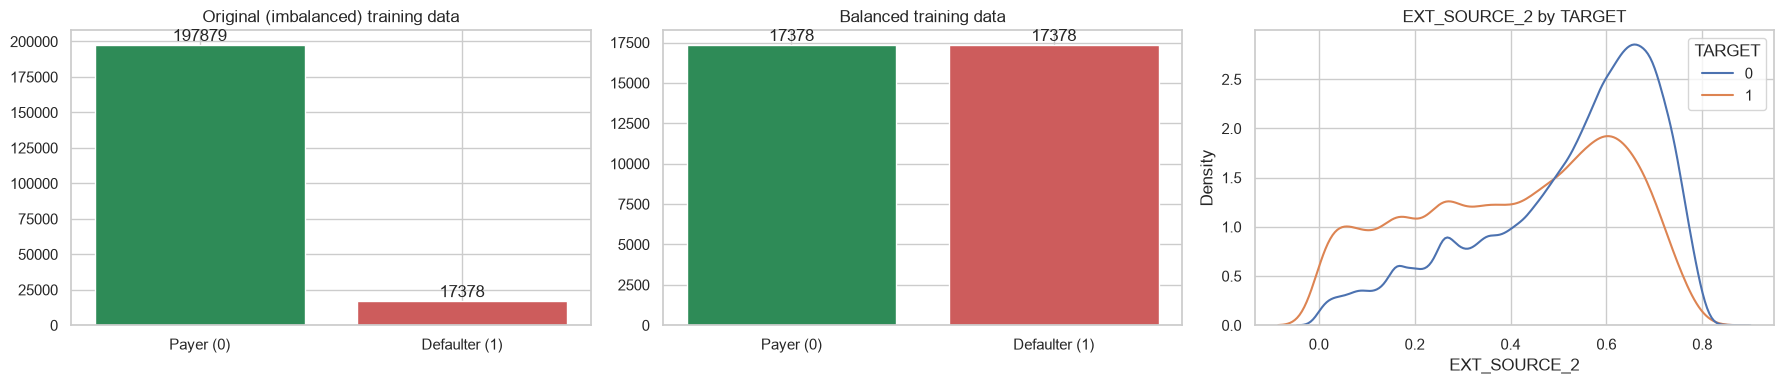

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (lab, yy) in zip(axes[:2], [("Original (imbalanced) training data", y_train), ("Balanced training data", y_bal)]):
    vc = pd.Series(yy).value_counts().sort_index()
    bars = ax.bar(["Payer (0)", "Defaulter (1)"], vc.values, color=["seagreen", "indianred"])
    ax.bar_label(bars); ax.set_title(lab)
d = df[["TARGET"]].assign(AGE=-df["DAYS_BIRTH"] / 365, EXT_SOURCE_2=df["EXT_SOURCE_2"])
sns.kdeplot(data=d, x="EXT_SOURCE_2", hue="TARGET", common_norm=False, ax=axes[2]); axes[2].set_title("EXT_SOURCE_2 by TARGET")
plt.tight_layout(); plt.show()

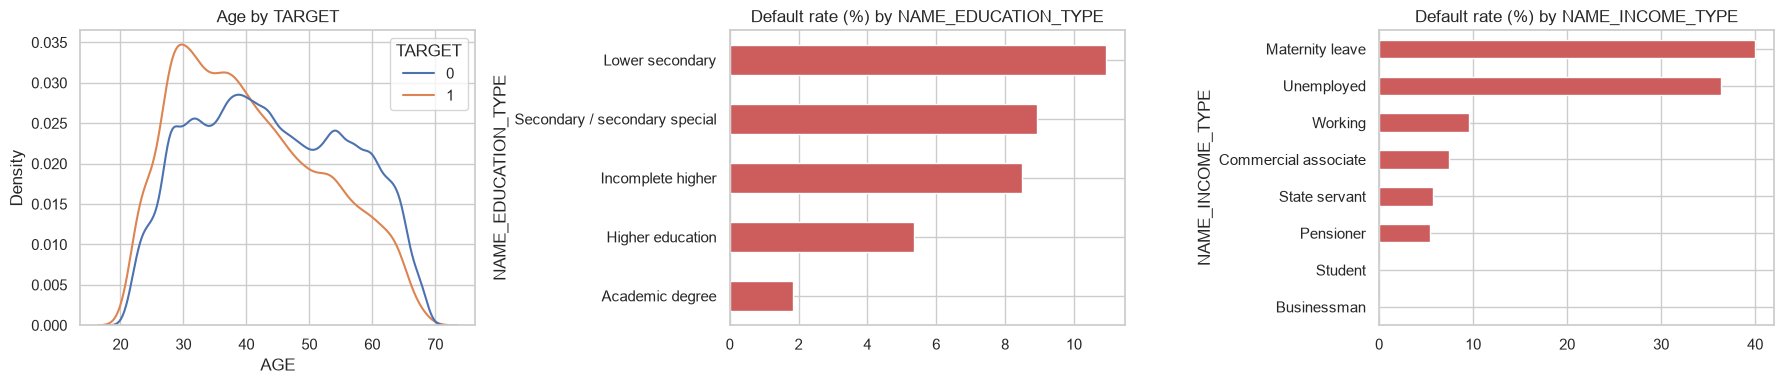

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.kdeplot(data=d, x="AGE", hue="TARGET", common_norm=False, ax=axes[0]); axes[0].set_title("Age by TARGET")
for ax, col in zip(axes[1:], ["NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE"]):
    r = df.groupby(col)["TARGET"].mean().sort_values() * 100
    r.plot.barh(ax=ax, color="indianred"); ax.set_title(f"Default rate (%) by {col}")
plt.tight_layout(); plt.show()

Younger applicants, lower education levels and low external credit scores (`EXT_SOURCE_*`) are associated with higher default rates.

## Deep learning model (Keras / TensorFlow)

In [10]:
def build_model(n_features):
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
        keras.layers.BatchNormalization(), keras.layers.Dropout(0.4),
        keras.layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
        keras.layers.BatchNormalization(), keras.layers.Dropout(0.4),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(5e-4), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="sensitivity"), "accuracy"])
    return model

model = build_model(X_bal.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        48,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,137 (356.00 KB)

 Trainable params: 90,369 (353.00 KB)

 Non-trainable params: 768 (3.00 KB)

Epochs trained: 22


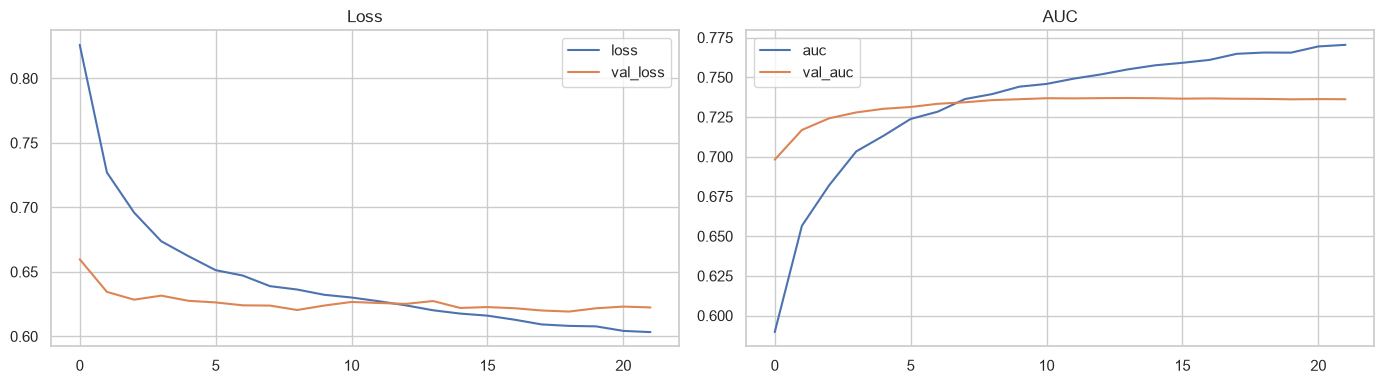

In [11]:
early = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8, restore_best_weights=True)
reduce = keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=3)
history = model.fit(X_bal, y_bal, validation_data=(X_val_s, y_val), epochs=60, batch_size=256,
                    callbacks=[early, reduce], verbose=0)
print("Epochs trained:", len(history.history["loss"]))
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hist[["loss", "val_loss"]].plot(ax=axes[0], title="Loss"); hist[["auc", "val_auc"]].plot(ax=axes[1], title="AUC")
plt.tight_layout(); plt.show()

## 7. Sensitivity  &  8. Area under the ROC curve (test set)

Sensitivity (recall of defaulters): 0.6735
Specificity (recall of payers):     0.6878
ROC-AUC:                            0.7437

              precision    recall  f1-score   support

       Payer      0.960     0.688     0.801     56538
   Defaulter      0.159     0.674     0.258      4965

    accuracy                          0.687     61503
   macro avg      0.560     0.681     0.530     61503
weighted avg      0.895     0.687     0.758     61503



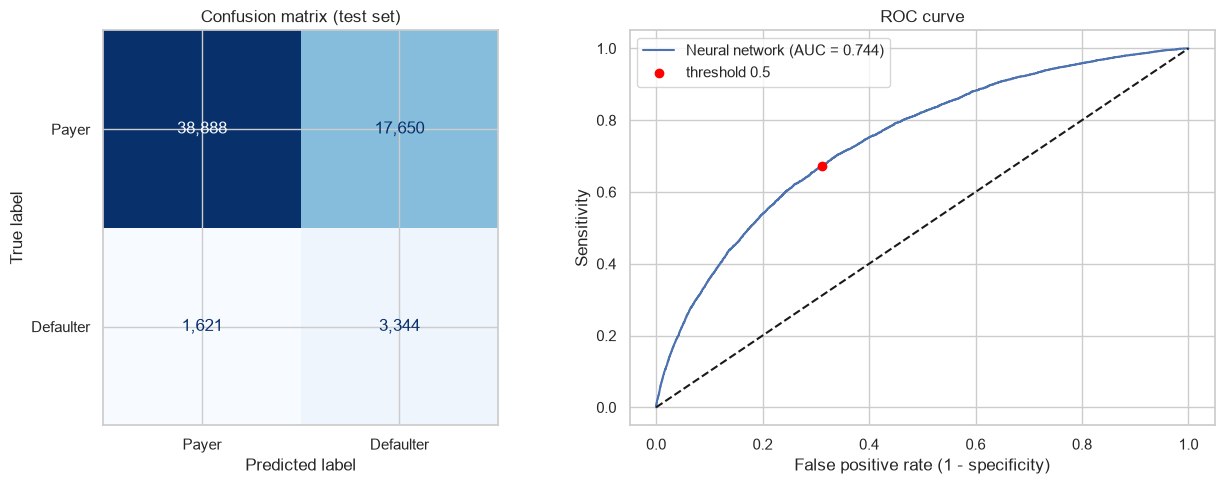

In [12]:
proba = model.predict(X_test_s, batch_size=4096, verbose=0).ravel()
pred = (proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
auc = roc_auc_score(y_test, proba)
print(f"Sensitivity (recall of defaulters): {sensitivity:.4f}")
print(f"Specificity (recall of payers):     {specificity:.4f}")
print(f"ROC-AUC:                            {auc:.4f}\n")
print(classification_report(y_test, pred, target_names=["Payer", "Defaulter"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Payer", "Defaulter"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
axes[0].set_title("Confusion matrix (test set)")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"Neural network (AUC = {auc:.3f})"); axes[1].plot([0, 1], [0, 1], "k--")
axes[1].scatter(1 - specificity, sensitivity, color="red", zorder=3, label="threshold 0.5")
axes[1].set_xlabel("False positive rate (1 - specificity)"); axes[1].set_ylabel("Sensitivity"); axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout(); plt.show()

## Conclusion
* Only ~8% of applicants default, so the training data was **balanced by under-sampling**; validation/test sets keep the true distribution.
* After dropping very sparse columns, imputing, label/one-hot encoding and scaling, a 3-layer **Keras** network was trained with dropout,
  batch normalisation and early stopping.
* On unseen test data the model reaches a **ROC-AUC of ≈ 0.74** with **sensitivity ≈ 0.67** (specificity ≈ 0.69) — it flags roughly two-thirds of
  future defaulters while correctly approving most good payers (see the metrics above).
* Strongest risk signals: low external credit scores (`EXT_SOURCE_*`), younger age, lower education and certain income types.
* The 0.5 threshold can be moved along the ROC curve: lowering it raises sensitivity (fewer missed defaults) at the cost of rejecting more good applicants.